# Fase D — Visualizaciones finales de los modelos

**Proyecto 2 y 3 · Introducción a la Ciencia de los Datos · Hurto de motocicletas en Colombia**

**Pregunta de negocio:** ¿es posible predecir la cantidad de hurtos de **motocicletas** que se presentarán en un **municipio** durante el **siguiente mes**, utilizando el comportamiento histórico de los hurtos y las variables disponibles en el dataset?

Este notebook reentrena los modelos de la Fase C con la **misma configuración y la misma semilla**, y produce las visualizaciones finales para el informe y la presentación. Cada figura se guarda en la carpeta `figuras/`.

| Visualización | Qué muestra |
|---|---|
| 1. Comparación de métricas | MAE, RMSE y R² de los 3 modelos y el baseline, en las dos validaciones |
| 2. Predicho vs real | qué tan cerca de la diagonal quedan las predicciones de 2025–2026 |
| 3. Serie real vs predicha | el pronóstico mes a mes en 4 municipios concretos |
| 4. Clusters visualizados | los 5 segmentos de K-Means y dónde aporta el modelo |

**¿Y la matriz de confusión o la curva ROC?** Son métricas de **clasificación** (el objetivo es una categoría, por ejemplo "sube / baja"). Nuestro objetivo es un **número** (cuántas motos se hurtan), es decir, un problema de **regresión**: sus visualizaciones equivalentes son la dispersión predicho vs real y el análisis de errores.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
SEMILLA = 42                                   # la misma de la Fase C -> mismos resultados
COLORES = {"Baseline (mes anterior)": "gray", "Regresión Lineal": "steelblue",
           "Gradient Boosting": "darkorange", "Random Forest": "seagreen"}
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

def guardar(fig, nombre):
    """Guarda la figura en figuras/ para usarla en el informe y la presentación."""
    fig.savefig(FIG / nombre, bbox_inches="tight")
    print(f"Guardada: figuras/{nombre}")

## 1. Datos y modelos (misma configuración de la Fase C)
Usamos `datos_limpios.parquet`, las mismas 53 variables predictoras y los mismos hiperparámetros. Entrenamos en las dos validaciones de la Fase C:
- **Split aleatorio 80/20** (`train_test_split`, evaluación principal del trabajo).
- **Prueba de futuro:** entrenar con 2012–2024 y probar con 2025 – julio 2026.

In [2]:
df = pd.read_parquet("datos_limpios.parquet").sort_values(["LLAVE_MUN", "FECHA_MES"]).reset_index(drop=True)
TARGET = "MOTOS"
EXCLUIR = (["LLAVE_MUN", "FECHA_MES", "CONJUNTO", TARGET, "MOTOS_LOG", "AUTOS", "AUTOS_LOG"]
           + [c for c in df.columns if c.endswith("_ESC")])
X, y = df.drop(columns=EXCLUIR), df[TARGET]

def crear_modelos():
    """Los tres modelos supervisados con los hiperparámetros de la Fase C."""
    return {
        "Regresión Lineal": Pipeline([("escalador", StandardScaler()), ("regresion", LinearRegression())]),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4,
                                                       subsample=0.8, random_state=SEMILLA),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5,
                                               n_jobs=-1, random_state=SEMILLA),
    }

def evaluar(nombre, validacion, y_real, y_pred):
    return {"Validación": validacion, "Modelo": nombre,
            "MAE": mean_absolute_error(y_real, y_pred), "MSE": mean_squared_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)), "R²": r2_score(y_real, y_pred)}

# Las dos particiones: el escalado va dentro del Pipeline (se ajusta solo con train)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEMILLA)
es_train = (df["CONJUNTO"] == "train").values
particiones = {"Split aleatorio 80/20": (X_tr, X_te, y_tr, y_te),
               "Prueba de futuro 2025-26": (X[es_train], X[~es_train], y[es_train], y[~es_train])}

metricas, predicciones = [], {}
for validacion, (a_tr, a_te, b_tr, b_te) in particiones.items():
    metricas.append(evaluar("Baseline (mes anterior)", validacion, b_te, a_te["MOTOS_LAG1"]))
    for nombre, modelo in crear_modelos().items():
        pred = np.clip(modelo.fit(a_tr, b_tr).predict(a_te), 0, None)   # no existen hurtos negativos
        predicciones[(validacion, nombre)] = pd.Series(pred, index=a_te.index)
        metricas.append(evaluar(nombre, validacion, b_te, pred))

metricas = pd.DataFrame(metricas)
metricas.round(3)

,Validación,Modelo,MAE,MSE,RMSE,R²
0,Split aleatorio 80/20,Baseline (mes anterior),0.915,12.762,3.572,0.967
1,Split aleatorio 80/20,Regresión Lineal,0.847,9.703,3.115,0.975
2,Split aleatorio 80/20,Gradient Boosting,0.874,11.711,3.422,0.969
3,Split aleatorio 80/20,Random Forest,0.853,10.111,3.180,0.974
4,Prueba de futuro 2025-26,Baseline (mes anterior),1.069,23.318,4.829,0.947
5,Prueba de futuro 2025-26,Regresión Lineal,0.968,15.749,3.969,0.964
6,Prueba de futuro 2025-26,Gradient Boosting,0.985,19.545,4.421,0.955
7,Prueba de futuro 2025-26,Random Forest,0.977,17.697,4.207,0.960


## 2. Comparación de métricas en las dos validaciones
**Qué vamos a ver:** el MAE (error promedio en motos), el RMSE (castiga los errores grandes) y el R² de cada modelo, comparando la validación aleatoria con la prueba de futuro. Las etiquetas indican cuánto mejora cada modelo frente al baseline.

Guardada: figuras/d1_comparacion_metricas.png


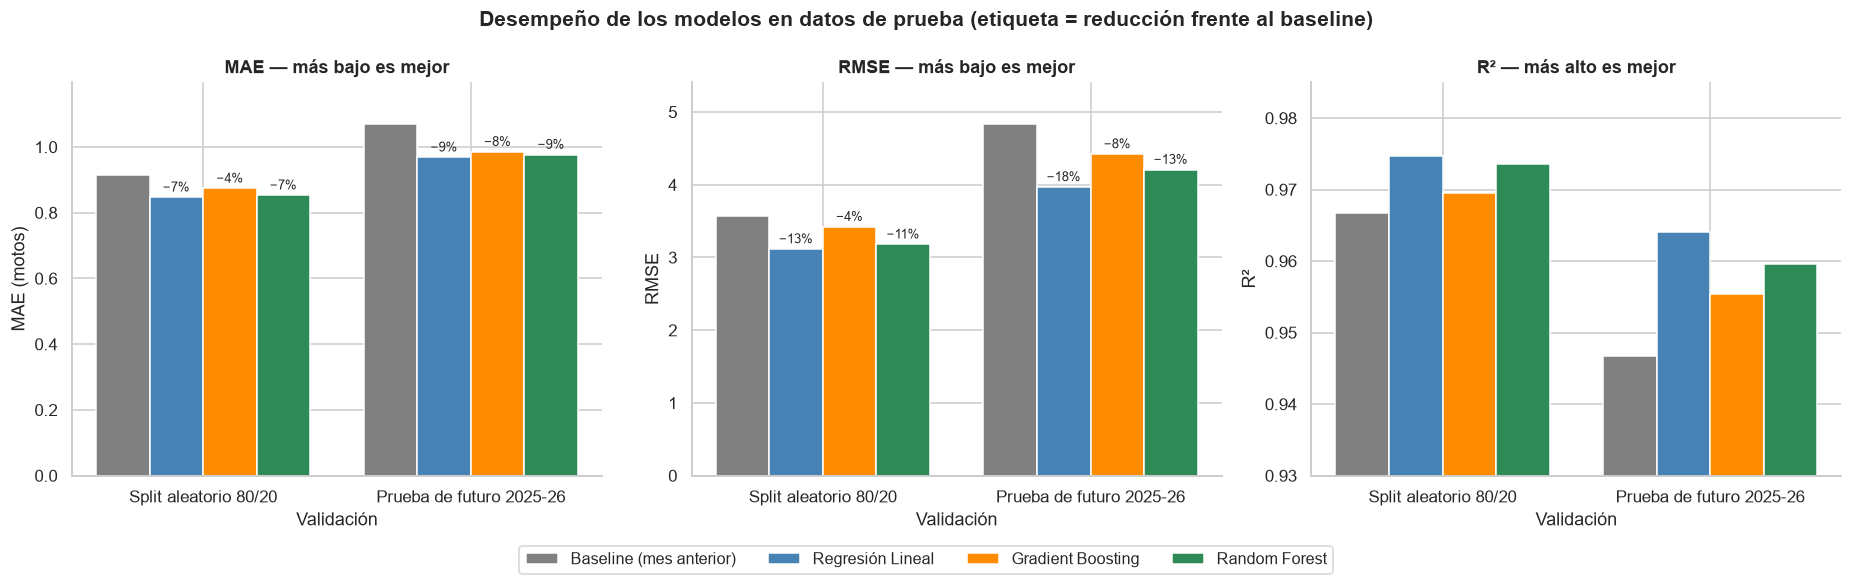

In [3]:
orden = list(COLORES)
validaciones = list(particiones)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ancho = 0.2
for ax, met in zip(axes, ["MAE", "RMSE", "R²"]):
    for j, modelo in enumerate(orden):
        vals = [metricas.query("Modelo == @modelo and `Validación` == @v")[met].iloc[0] for v in validaciones]
        barras = ax.bar(np.arange(2) + (j - 1.5) * ancho, vals, ancho, color=COLORES[modelo], label=modelo)
        if met != "R²" and modelo != "Baseline (mes anterior)":
            base = [metricas.query("Modelo == 'Baseline (mes anterior)' and `Validación` == @v")[met].iloc[0] for v in validaciones]
            ax.bar_label(barras, labels=[f"−{1 - v / b:.0%}" for v, b in zip(vals, base)], fontsize=8.5, padding=2)
    ax.set_xticks(range(2), labels=validaciones)
    ax.set_xlabel("Validación")
    ax.set_ylabel(met + (" (motos)" if met == "MAE" else ""))
    ax.set_title(met + (" — más alto es mejor" if met == "R²" else " — más bajo es mejor"))
    if met == "R²":
        ax.set_ylim(0.93, 0.985)
    else:
        ax.set_ylim(0, metricas[met].max() * 1.12)
manijas, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(manijas, etiquetas, loc="lower center", ncol=4, fontsize=10.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Desempeño de los modelos en datos de prueba (etiqueta = reducción frente al baseline)", fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "d1_comparacion_metricas.png")
plt.show()

**Insight:** la **Regresión Lineal gana en las tres métricas y en las dos validaciones**. En la prueba de futuro todos los errores suben (el MAE de la lineal pasa de 0,85 a 0,97), pero la **ventaja frente al baseline crece**: la lineal reduce el RMSE un 18 % y el MAE un 9 %, frente a 13 % y 7 % en el split aleatorio. Es decir, los modelos aportan más justamente en la situación real de uso: predecir hacia adelante. Gradient Boosting es el que menos mejora al baseline en ambos casos.

## 3. Predicho vs real (prueba de futuro 2025 – jul 2026)
**Qué vamos a ver:** cada celda hexagonal agrupa municipio-meses de 2025–2026 según las motos **reales** (eje X) y las **predichas** (eje Y); ambos ejes en escala log(1 + x). La línea punteada es la predicción perfecta. Usamos la prueba de futuro porque es la situación real de uso: el modelo solo conoce el pasado.

Guardada: figuras/d2_predicho_vs_real.png


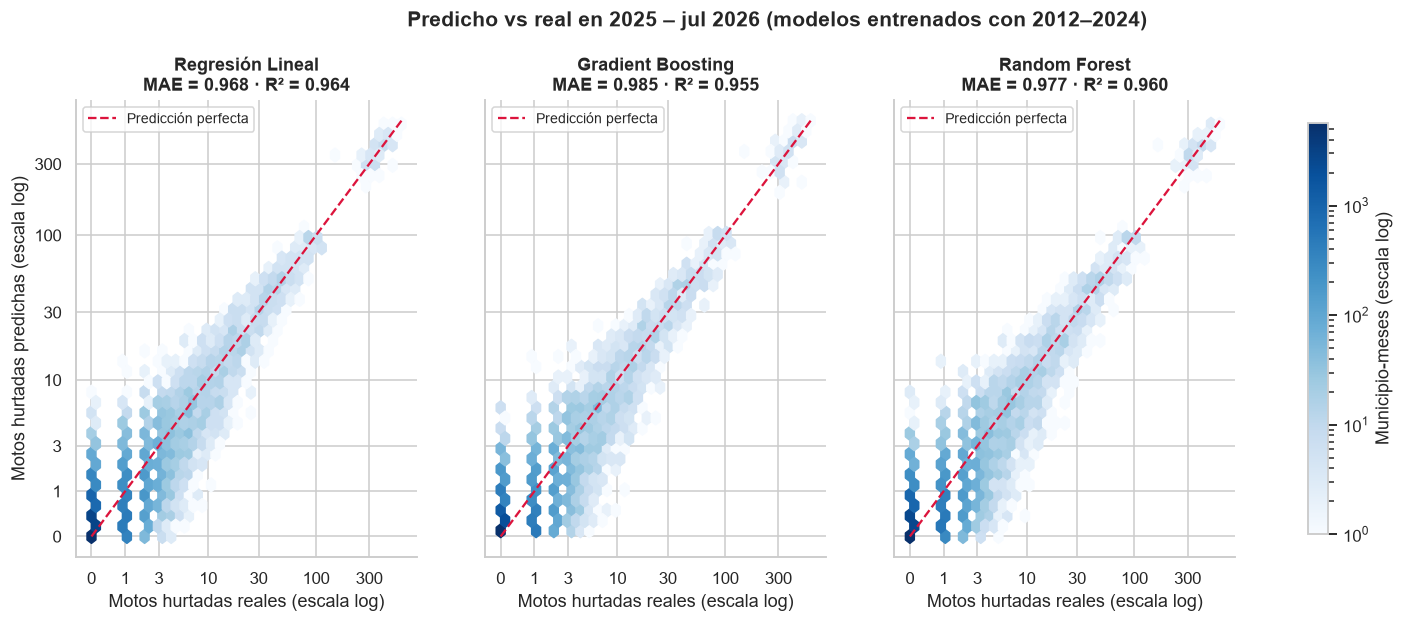

Regresión Lineal: error menor a 1 moto en el 79.7% de los municipio-meses
Gradient Boosting: error menor a 1 moto en el 81.4% de los municipio-meses
Random Forest: error menor a 1 moto en el 81.2% de los municipio-meses


In [4]:
val = "Prueba de futuro 2025-26"
y_fut = y[~es_train]
tope = np.log1p(max(y_fut.max(), max(predicciones[(val, m)].max() for m in orden[1:])))
marcas = [m for m in [0, 1, 3, 10, 30, 100, 300] if np.log1p(m) <= tope]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), sharex=True, sharey=True)
for ax, modelo in zip(axes, orden[1:]):
    pred = predicciones[(val, modelo)]
    hb = ax.hexbin(np.log1p(y_fut), np.log1p(pred), gridsize=35, bins="log", cmap="Blues", mincnt=1)
    ax.plot([0, tope], [0, tope], ls="--", color="crimson", lw=1.5, label="Predicción perfecta")
    m = metricas.query("Modelo == @modelo and `Validación` == @val").iloc[0]
    ax.set_title(f"{modelo}\nMAE = {m['MAE']:.3f} · R² = {m['R²']:.3f}")
    ax.set_xticks(np.log1p(marcas), labels=marcas); ax.set_yticks(np.log1p(marcas), labels=marcas)
    ax.set_xlabel("Motos hurtadas reales (escala log)")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Motos hurtadas predichas (escala log)")
fig.colorbar(hb, ax=axes, label="Municipio-meses (escala log)", shrink=0.9)
fig.suptitle("Predicho vs real en 2025 – jul 2026 (modelos entrenados con 2012–2024)", fontsize=14, fontweight="bold", y=1.03)
guardar(fig, "d2_predicho_vs_real.png")
plt.show()

# ¿Qué tan seguido acierta "casi exacto"?
for modelo in orden[1:]:
    err = (y_fut - predicciones[(val, modelo)]).abs()
    print(f"{modelo}: error menor a 1 moto en el {(err < 1).mean():.1%} de los municipio-meses")

**Insight:** los tres modelos siguen la diagonal desde 1 hasta más de 500 motos al mes, y en el **80–81 % de los municipio-meses se equivocan en menos de 1 moto**. Los modelos de árboles aciertan "casi exacto" un poco más seguido (81 % frente a 80 %), pero la lineal tiene menor MAE y RMSE porque se equivoca menos en las ciudades grandes, donde los errores pesan más. La debilidad compartida está abajo a la izquierda: cuando el mes real es 0, los modelos a veces predicen entre 1 y 5 motos.

## 4. Serie real vs predicha en municipios concretos
**Qué vamos a ver:** mes a mes en 2025 – jul 2026, las motos hurtadas **reales** frente al pronóstico del modelo elegido (Regresión Lineal) y del baseline, en las 3 ciudades más grandes y en Soacha, un municipio del segmento "intermedios en crecimiento". Cada pronóstico se hace con la información disponible al final del mes anterior.

Guardada: figuras/d3_serie_real_vs_predicha.png


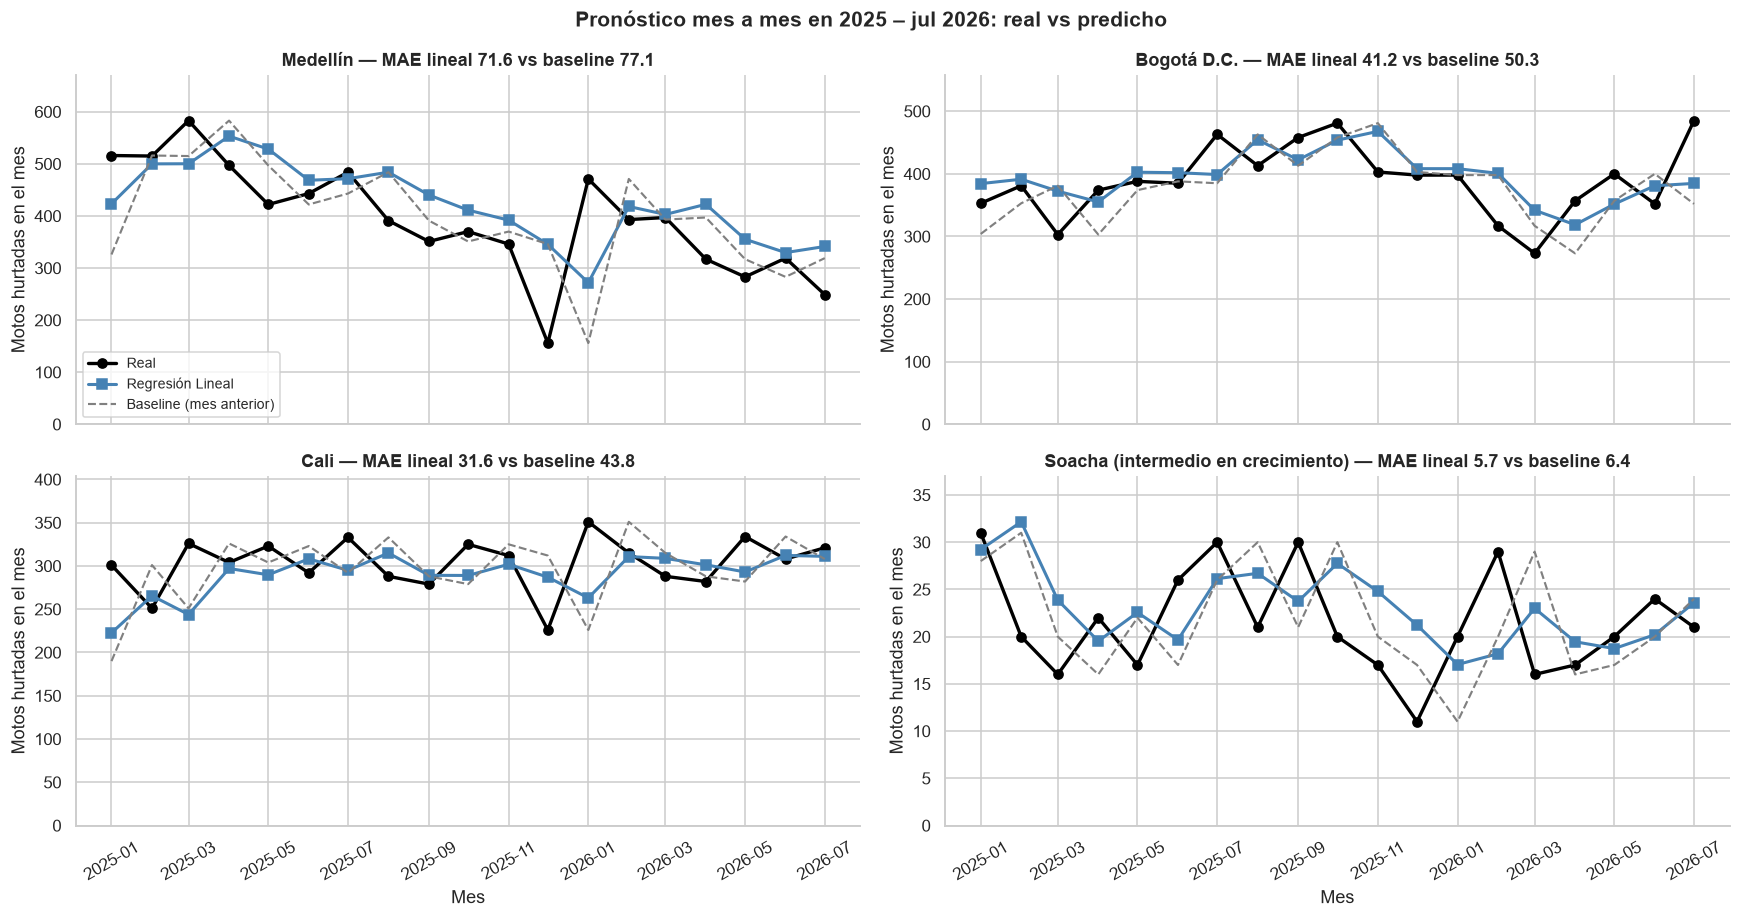

,Municipio,Motos/mes reales,MAE lineal,MAE baseline,Error lineal (% del real)
0,Medellín,394.9,71.6,77.1,18.1
1,Bogotá D.C.,388.5,41.2,50.3,10.6
2,Cali,303.1,31.6,43.8,10.4
3,Soacha (intermedio en crecimiento),21.5,5.7,6.4,26.6


In [5]:
pred_lin = predicciones[(val, "Regresión Lineal")]
futuro = df.loc[~es_train, ["LLAVE_MUN", "FECHA_MES", "MOTOS", "MOTOS_LAG1"]].assign(pred=pred_lin)
ciudades = {"ANTIOQUIA | MEDELLIN": "Medellín", "BOGOTA | BOGOTA D.C.": "Bogotá D.C.",
            "VALLE | CALI": "Cali", "CUNDINAMARCA | SOACHA": "Soacha (intermedio en crecimiento)"}

fig, axes = plt.subplots(2, 2, figsize=(16, 8.5), sharex=True)
resumen_ciudades = []
for ax, (llave, nombre) in zip(axes.ravel(), ciudades.items()):
    d = futuro[futuro["LLAVE_MUN"] == llave]
    ax.plot(d["FECHA_MES"], d["MOTOS"], color="black", marker="o", lw=2.2, label="Real")
    ax.plot(d["FECHA_MES"], d["pred"], color="steelblue", marker="s", lw=2, label="Regresión Lineal")
    ax.plot(d["FECHA_MES"], d["MOTOS_LAG1"], color="gray", ls="--", lw=1.4, label="Baseline (mes anterior)")
    mae_l, mae_b = mean_absolute_error(d["MOTOS"], d["pred"]), mean_absolute_error(d["MOTOS"], d["MOTOS_LAG1"])
    resumen_ciudades.append({"Municipio": nombre, "Motos/mes reales": d["MOTOS"].mean(), "MAE lineal": mae_l,
                             "MAE baseline": mae_b, "Error lineal (% del real)": mae_l / d["MOTOS"].mean() * 100})
    ax.set_title(f"{nombre} — MAE lineal {mae_l:.1f} vs baseline {mae_b:.1f}")
    ax.set_ylabel("Motos hurtadas en el mes")
    ax.set_ylim(0, max(d["MOTOS"].max(), d["pred"].max(), d["MOTOS_LAG1"].max()) * 1.15)
for ax in axes[1]:
    ax.set_xlabel("Mes")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(loc="lower left", fontsize=9)
fig.suptitle("Pronóstico mes a mes en 2025 – jul 2026: real vs predicho", fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "d3_serie_real_vs_predicha.png")
plt.show()
pd.DataFrame(resumen_ciudades).round(1)

**Insight:** el modelo sigue el **nivel y la tendencia** de cada ciudad y suaviza los saltos que el baseline copia con un mes de retraso. En Cali reduce el error de 43,8 a 31,6 motos al mes (−28 %) y en Bogotá de 50,3 a 41,2 (−18 %); en ambas el error equivale a **≈ 10 % del volumen mensual**. Ningún modelo anticipa caídas bruscas como la de Medellín en diciembre de 2025 (156 motos frente a ≈ 350 habituales), parecida al hueco de registro visto en 2012; por eso Medellín tiene el mayor error relativo (18 %). En municipios intermedios como Soacha (≈ 21 motos/mes) el error relativo es mayor (27 %), porque con pocos casos el azar pesa más.

## 5. Clusters visualizados: segmentos de K-Means y valor del modelo
**Qué vamos a ver:** a la izquierda, los 1.042 municipios agrupados por K-Means (k = 5, mismo perfil y semilla de la Fase C), proyectados en 2D con PCA. A la derecha, para cada segmento, cuánto **reduce el error** la Regresión Lineal frente al baseline en la prueba de futuro (barras a la derecha = el modelo ayuda; a la izquierda = el baseline es mejor).

Guardada: figuras/d4_clusters_y_error.png


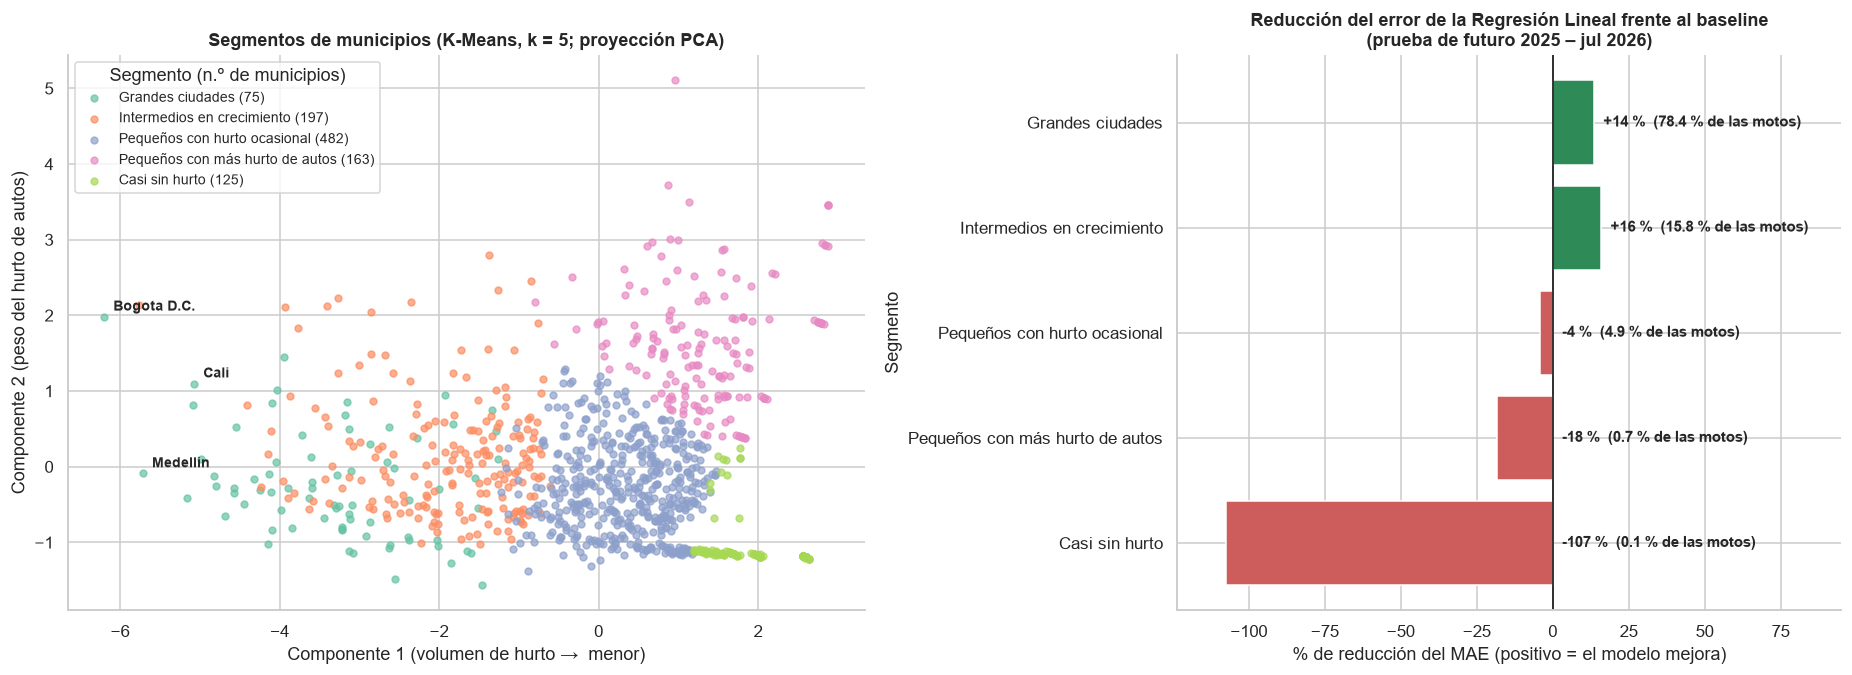

,municipios,% de las motos 2025-26,MAE baseline,MAE lineal,Reducción del error
segmento,,,,,
Grandes ciudades,75.0,78.39,7.18,6.20,13.64
Intermedios en crecimiento,197.0,15.84,1.68,1.41,16.02
Pequeños con hurto ocasional,482.0,4.94,0.43,0.44,-4.10
Pequeños con más hurto de autos,163.0,0.70,0.20,0.24,-18.45
Casi sin hurto,125.0,0.13,0.06,0.12,-107.38


In [6]:
hist_train = df[df["CONJUNTO"] == "train"]

def perfil_municipio(g):
    """Perfil del hurto de un municipio (igual que en la Fase C)."""
    motos, autos = g["MOTOS"], g["AUTOS"]
    inicio = motos[g["ANIO"].between(2012, 2014)].mean()
    final = motos[g["ANIO"].between(2022, 2024)].mean()
    return pd.Series({
        "volumen_log": np.log1p(motos.mean()),
        "pct_meses_cero": (motos == 0).mean() * 100,
        "variabilidad": motos.std() / motos.mean() if motos.mean() > 0 else 0.0,
        "tendencia": np.log1p(final) - np.log1p(inicio),
        "pct_autos": autos.sum() / (motos.sum() + autos.sum()) * 100 if (motos.sum() + autos.sum()) > 0 else 0.0,
        "prom_motos_mes": motos.mean(),
    })

perfiles = hist_train.groupby("LLAVE_MUN").apply(perfil_municipio)
VARS_CLUSTER = ["volumen_log", "pct_meses_cero", "variabilidad", "tendencia", "pct_autos"]
modelo_km = Pipeline([("escalador", StandardScaler()), ("kmeans", KMeans(n_clusters=5, n_init=20, random_state=SEMILLA))])
perfiles["grupo"] = modelo_km.fit_predict(perfiles[VARS_CLUSTER])
orden_grupos = perfiles.groupby("grupo")["prom_motos_mes"].mean().sort_values(ascending=False).index
NOMBRES = dict(zip(orden_grupos, ["Grandes ciudades", "Intermedios en crecimiento", "Pequeños con hurto ocasional",
                                  "Pequeños con más hurto de autos", "Casi sin hurto"]))
perfiles["segmento"] = perfiles["grupo"].map(NOMBRES)
Z = modelo_km.named_steps["escalador"].transform(perfiles[VARS_CLUSTER])
P = PCA(n_components=2, random_state=SEMILLA).fit_transform(Z)

# Error por segmento en la prueba de futuro
futuro["segmento"] = futuro["LLAVE_MUN"].map(perfiles["segmento"])
por_seg = (futuro.groupby("segmento")
           .apply(lambda d: pd.Series({"municipios": d["LLAVE_MUN"].nunique(),
                                       "% de las motos 2025-26": d["MOTOS"].sum(),
                                       "MAE baseline": mean_absolute_error(d["MOTOS"], d["MOTOS_LAG1"]),
                                       "MAE lineal": mean_absolute_error(d["MOTOS"], d["pred"])}))
           .loc[list(NOMBRES.values())])
por_seg["% de las motos 2025-26"] = por_seg["% de las motos 2025-26"] / futuro["MOTOS"].sum() * 100
por_seg["Reducción del error"] = (1 - por_seg["MAE lineal"] / por_seg["MAE baseline"]) * 100

paleta = dict(zip(NOMBRES.values(), sns.color_palette("Set2", 5)))
fig, axes = plt.subplots(1, 2, figsize=(17, 6.3), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for seg, color in paleta.items():
    m = (perfiles["segmento"] == seg).values
    ax.scatter(P[m, 0], P[m, 1], s=20, alpha=0.7, color=color, label=f"{seg} ({m.sum()})")
for llave in perfiles.nlargest(3, "prom_motos_mes").index:
    i = perfiles.index.get_loc(llave)
    ax.annotate(llave.split(" | ")[1].title(), P[i], xytext=(6, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_title("Segmentos de municipios (K-Means, k = 5; proyección PCA)")
ax.set_xlabel("Componente 1 (volumen de hurto →  menor)")
ax.set_ylabel("Componente 2 (peso del hurto de autos)")
ax.legend(title="Segmento (n.º de municipios)", fontsize=9)

ax = axes[1]
vals = por_seg["Reducción del error"]
ax.barh(range(len(vals)), vals.values[::-1], color=["seagreen" if v > 0 else "indianred" for v in vals.values[::-1]])
# Etiquetas siempre a la derecha del cero para que no se monten sobre las barras negativas
for i, (v, p) in enumerate(zip(vals.values[::-1], por_seg["% de las motos 2025-26"].values[::-1])):
    ax.text(max(v, 0) + 3, i, f"{v:+.0f} %  ({p:.1f} % de las motos)", va="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(range(len(vals)), labels=vals.index[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlim(min(vals.min() * 1.15, -10), 95)
ax.set_title("Reducción del error de la Regresión Lineal frente al baseline\n(prueba de futuro 2025 – jul 2026)")
ax.set_xlabel("% de reducción del MAE (positivo = el modelo mejora)")
ax.set_ylabel("Segmento")
plt.tight_layout()
guardar(fig, "d4_clusters_y_error.png")
plt.show()
por_seg.round(2)

**Insight:** el modelo aporta **donde está el problema**. En las **grandes ciudades** (78 % de las motos hurtadas en 2025–26) reduce el error un 14 %, y en los **intermedios en crecimiento** (16 %) un 16 %. En los tres segmentos pequeños (menos del 6 % de los casos) el baseline es mejor: en "Casi sin hurto" el modelo duplica el error (0,12 frente a 0,06) porque predice fracciones de moto donde casi siempre hay 0. **Recomendación de uso:** aplicar el modelo en los 272 municipios de los dos primeros segmentos, que concentran el 94 % de los casos, y la regla "igual al mes anterior" en el resto.

## Resumen de las visualizaciones finales

| Figura | Archivo | Mensaje principal |
|---|---|---|
| Comparación de métricas | `figuras/d1_comparacion_metricas.png` | La Regresión Lineal es la mejor en las dos validaciones; su ventaja crece al predecir el futuro |
| Predicho vs real | `figuras/d2_predicho_vs_real.png` | En el 80 % de los municipio-meses el error es menor a 1 moto |
| Serie real vs predicha | `figuras/d3_serie_real_vs_predicha.png` | En Bogotá y Cali el error es ≈ 10 % del volumen mensual; las caídas bruscas no se anticipan |
| Clusters y error | `figuras/d4_clusters_y_error.png` | El modelo mejora al baseline en los segmentos que concentran el 94 % de los casos |

Estas figuras, junto con 3 gráficos clave del EDA, son las que se usan en el informe final (`informe_p2p3`) y en la presentación.